# 04 · NeuMF, GMF, MLP and NeuMF-pre on Yelp

Thesis §5.3.2, §5.4.2, §5.5.2, §5.7.2 · Tables 9, 11, 13, 17 · Figures 12–13, 16–17, 20–21, 28–29

The same protocol as notebook 02, applied to Yelp. The saved outputs are the runs reported in the thesis:
NeuMF (Table 13), GMF (Table 9) and MLP (Table 11). The cell after the NeuMF run re-plots its logged
history (Figures 20–21).

The NeuMF-pre cell pretrains GMF for 3 epochs and MLP for 6 epochs. Its saved output stops after the
first validation step. The value in Table 17 comes from the learning-rate grid
{1e-4, 5e-4, 1e-3, 5e-3} (best: 1e-4), which was run separately and is not part of this notebook.

In [ ]:
# Folder containing ml-1m.ratings.dat and yelp.rating (see data/README.md).
# On Kaggle, point this at the attached dataset, e.g. "/kaggle/input/<dataset-name>".
DATA_DIR = "../data"

In [9]:
#Used libraries

import numpy as np
from tensorflow.keras.layers import (
    Input, Embedding, Flatten, Multiply, 
    Dense, Concatenate, Activation
)
import tensorflow as tf

from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
import pandas as pd
import numpy as np
from sklearn.preprocessing import LabelEncoder
import matplotlib.pyplot as plt
from collections import defaultdict
import random
import math

In [ ]:

#Plotting training and Validation accuracy
def plot_accuracy(history):
    plt.figure()
    acc_key = 'accuracy' if 'accuracy' in history.history else 'binary_accuracy'
    val_acc_key = 'val_' + acc_key

    plt.plot(history.history[acc_key], label='Train Accuracy')
    if val_acc_key in history.history:
        plt.plot(history.history[val_acc_key], label='Validation Accuracy')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend()



#HR (hit ratio)
def HR(ranked_predicted_list, true_test_item, number_of_rec_items = 10):
    top_rec_items = ranked_predicted_list[:number_of_rec_items]
    item_ids = [item_id for item_id, _ in top_rec_items]
    if true_test_item in item_ids:
        return 1.0
    else:
        return 0.0
#Normalized Discounted Cumulative Gain (NDCG) 


def NDCG(ranked_predicted_list, true_test_item, number_of_rec_items):
    top_rec_items = ranked_predicted_list[:number_of_rec_items]
    item_ids = [item_id for item_id, _ in top_rec_items]
    for rank, item_id in enumerate(item_ids):
        if item_id == true_test_item:
            return 1.0/math.log2((rank+1) +1)
    return 0



#Get the predictions


#Evaluation using HR
def eval_hr_ndcg(
    interaction_matrix,
    interaction_array,
    test_df,
    model,
    number_of_rec_items,
    max_test_size,
    neg_sample_size=100,
):
    user_index_list = interaction_matrix.index.tolist()
    item_index_list = interaction_matrix.columns.tolist()

    user2pivot = {uid: idx for idx, uid in enumerate(user_index_list)}
    item2pivot = {iid: idx for idx, iid in enumerate(item_index_list)}

    # Build user -> set(positive items) from interaction_array
    user_item_dict = defaultdict(set)
    n_users = interaction_array.shape[0]
    for user in range(n_users):
        item_positions = np.where(interaction_array[user] == 1)[0]
        user_item_dict[user] = set(item_positions)

    all_items = list(range(num_items))  # uses global num_items

    users = test_df['user_id'].values
    items = test_df['item_id'].values

    num_hits = 0.0
    num_test = 0.0
    sum_ndcg = 0.0

    for df_user, df_item in zip(users, items):
        # skip users/items not in pivot
        if (df_user not in user2pivot) or (df_item not in item2pivot):
            continue

        user_idx = user2pivot[df_user]
        item_idx = item2pivot[df_item]

        items_interacted = user_item_dict[user_idx]
        possible_sample_of_neg = list(set(all_items) - items_interacted - {item_idx})

        if len(possible_sample_of_neg) == 0:
            continue

        # sample min(neg_sample_size, len(candidates)) negatives
        n_neg = min(neg_sample_size, len(possible_sample_of_neg))
        negative_sample = random.sample(possible_sample_of_neg, n_neg)

        test_sample_per_user = negative_sample + [item_idx]

        # model predictions
        array_of_users = np.full(len(test_sample_per_user), user_idx, dtype='int32')
        array_of_items = np.array(test_sample_per_user, dtype='int32')

        predictions = model.predict([array_of_users, array_of_items], verbose=0).flatten()
        test_sample_per_user_predictions = list(zip(test_sample_per_user, predictions))
        ranked_predicted_list = sorted(
            test_sample_per_user_predictions,
            key=lambda x: x[1],
            reverse=True
        )

        hit = HR(ranked_predicted_list, item_idx, number_of_rec_items=number_of_rec_items)
        ndcg_val = NDCG(ranked_predicted_list, item_idx, number_of_rec_items)

        sum_ndcg += ndcg_val
        num_hits += hit
        num_test += 1

        if max_test_size <= num_test:
            break

    if num_test == 0:
        average_num_hits = 0.0
        ndcg_k = 0.0
    else:
        average_num_hits = num_hits / num_test
        ndcg_k = sum_ndcg / num_test

    print(f"HR@{number_of_rec_items} = {average_num_hits:.4f}")
    print(f"NDCG@{number_of_rec_items} = {ndcg_k:.4f}")
    return average_num_hits, ndcg_k
    
   
    
#Get weights from pretrained models
def get_weights(gmf_model, mlp_model,neumf_model,hidden_units,alpha):
    
    #From GMF (emb layer):
    gmf_user_emb = gmf_model.get_layer('gmf_user_embedding').get_weights()
    gmf_item_emb = gmf_model.get_layer('gmf_item_embedding').get_weights()

    #From GMF (output layer)
    gmf_output_weights = gmf_model.get_layer('outputs').get_weights()  
        
    #To NeuMF from GMF
    #(Emb)
    neumf_model.get_layer('gmf_user_embedding').set_weights(gmf_user_emb)
    neumf_model.get_layer('gmf_item_embedding').set_weights(gmf_item_emb)

    #(Output)

    #neumf_model.get_layer('gmf_outputs').set_weights(gmf_output_weights)

    #From MLP (emb layer)
    mlp_user_emb = mlp_model.get_layer('user_embedding').get_weights()
    mlp_item_emb = mlp_model.get_layer('item_embedding').get_weights()
    #Fron MLP (layers)
    
    #From MLP (output layer)
    mlp_output_weights = mlp_model.get_layer('outputs').get_weights()  

    #To NeuMF from GMF
    #(Emb)
    neumf_model.get_layer('mlp_user_embedding').set_weights(mlp_user_emb)
    neumf_model.get_layer('mlp_item_embedding').set_weights(mlp_item_emb)
    #(Layers)
    for idx, _ in enumerate(hidden_units):
        mlp_layer_weights = mlp_model.get_layer(f"hidden_{idx}").get_weights()
        neumf_model.get_layer(f"mlp_hidden_{idx}").set_weights(mlp_layer_weights)
    #(Output)
    #neumf_model.get_layer('mlp_outputs').set_weights(mlp_output_weights)

    #Concatenate weights:
    Wg, bg = gmf_output_weights
    Wm, bm = mlp_output_weights
    W_final = np.concatenate([alpha * Wg, (1 - alpha) * Wm], axis=0)
    b_final = alpha * bg + (1 - alpha) * bm
    #Add concatenated weights and biases to the NEUMF
    neumf_model.get_layer('neumf_outputs').set_weights([W_final, b_final])
    
    print("Weights added")
    

    
    






Models:
1) GMF model: build_GMF
2) MLP model: build_MLP
3) NeuMF model: build_NEUMF

In [11]:
#GMF model

def build_GMF(num_users, num_items, learning_rate,emb_size):
    user_input = Input(shape=(1,), name='user_input')
    item_input = Input(shape=(1,), name='item_input')
    
    user_embedding = Embedding(
        input_dim=num_users, 
        output_dim=emb_size, 
        name='gmf_user_embedding'
    )
    item_embedding = Embedding(
        input_dim=num_items,
        output_dim=emb_size,
        name='gmf_item_embedding'
    )
    
    user_latent = Flatten()(user_embedding(user_input))
    item_latent = Flatten()(item_embedding(item_input))
    gmf_vector = Multiply()([user_latent, item_latent])
    
    outputs = Dense(1, activation='sigmoid', name='outputs')(gmf_vector)
    model = Model(
        inputs=[user_input,item_input],
        outputs=outputs
    )
    
    return model

#MPL model
def build_MLP(num_users, num_items, emb_size, hidden_units, learning_rate):
    user_input = Input(shape=(1,), name='user_input')   
    item_input = Input(shape=(1,), name='item_input')   

    user_embedding = Embedding(
        input_dim=num_users,
        output_dim=emb_size,
        name='user_embedding'
    )(user_input)
    user_embedding = Flatten()(user_embedding)

    item_embedding = Embedding(
        input_dim=num_items,
        output_dim=emb_size,
        name='item_embedding'
    )(item_input)
    item_embedding = Flatten()(item_embedding)

    concat_vec = Concatenate(axis=1)([user_embedding, item_embedding])
    x = concat_vec
    
    for idx, units in enumerate(hidden_units):
        x = Dense(units, activation='relu', name=f"hidden_{idx}")(x)
        
    outputs = Dense(1, activation='sigmoid', name='outputs')(x)
    
    model = Model(
        inputs=[user_input, item_input],
        outputs=outputs
    )
    return model


#NeuMF model

def build_NEUMF(
    num_users,
    num_items,
    latent_dim,      # currently unused, kept for API compatibility
    hidden_units,
    emb_size,
    learning_rate,
    alpha=0.5        # currently unused here; used in get_weights
):
    user_input = Input(shape=(1,), name='user_input')   
    item_input = Input(shape=(1,), name='item_input') 

    # ----- MLP branch -----
    mlp_user_embedding = Embedding(
        input_dim=num_users,
        output_dim=emb_size,
        name='mlp_user_embedding'
    )(user_input)
    mlp_user_embedding = Flatten()(mlp_user_embedding)

    mlp_item_embedding = Embedding(
        input_dim=num_items,
        output_dim=emb_size,
        name='mlp_item_embedding'
    )(item_input)
    mlp_item_embedding = Flatten()(mlp_item_embedding)

    mlp_concat_vec = Concatenate(axis=1)([mlp_user_embedding, mlp_item_embedding])
    x = mlp_concat_vec
    for idx, units in enumerate(hidden_units):
        x = Dense(units, activation='relu', name=f"mlp_hidden_{idx}")(x)
    mlp_vector = x

    # ----- GMF branch -----
    gmf_user_embedding = Embedding(
        input_dim=num_users, 
        output_dim=emb_size, 
        name='gmf_user_embedding'
    )
    gmf_item_embedding = Embedding(
        input_dim=num_items,
        output_dim=emb_size,
        name='gmf_item_embedding'
    )
    gmf_user_latent = Flatten()(gmf_user_embedding(user_input))
    gmf_item_latent = Flatten()(gmf_item_embedding(item_input))
    gmf_vector = Multiply()([gmf_user_latent, gmf_item_latent])

    # ----- NeuMF fusion -----
    neumf_concat = Concatenate(axis=1)([mlp_vector, gmf_vector])
    neumf_outputs = Dense(1, activation='sigmoid', name='neumf_outputs')(neumf_concat)

    model = Model(
        inputs=[user_input, item_input],
        outputs=neumf_outputs
    )
    # DO NOT compile here; you compile outside
    return model


In [ ]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import LabelEncoder
import os
import sys

def read_yelp_rating_file(file_path):
    # Check if the file exists
    if not os.path.exists(file_path):
        print(f"Error: File '{file_path}' does not exist.")
        sys.exit(1)

    try:
        # Read the file into a DataFrame (auto-detects whitespace or tab)
        df = pd.read_csv(
            file_path,
            sep=r'\s+',            # handles both tabs and spaces
            header=None,
            names=['user_id', 'item_id', 'rating', 'timestamp'],
            engine='python'        # allows regex separator
        )

        # Display basic information about the DataFrame
        print("✅ Data successfully loaded.\n")
        print("DataFrame Info:")
        print(df.info())
        print("\nFirst 5 rows of the DataFrame:")
        print(df.head())

        return df

    except Exception as e:
        print(f" Error reading file '{file_path}': {e}")
        sys.exit(1)

yelp_file_path = f"{DATA_DIR}/yelp.rating"
yelp_df = read_yelp_rating_file(yelp_file_path)
df = yelp_df
# -----------------------------
# 1. Basic sanity check
# -----------------------------
user_counts = df.groupby("user_id").size()
print("Minimum number of ratings per user:", user_counts.min())

# -----------------------------
# 2. Leave-one-out split: train / test
# -----------------------------
# Sort by user, then timestamp
df = df.sort_values(['user_id', 'timestamp'])

train_list = []
test_list  = []

for user_id, group in df.groupby('user_id'):
    user_history = group.values  # or group.to_numpy()

    # Last interaction = test
    test_interaction = user_history[-1]
    # All previous = train
    train_interactions = user_history[:-1]

    for row in train_interactions:
        train_list.append(row)
    test_list.append(test_interaction)

train_df = pd.DataFrame(train_list, columns=df.columns).reset_index(drop=True)
test_df  = pd.DataFrame(test_list,  columns=df.columns).reset_index(drop=True)

# -----------------------------
# 3. Validation split from train (second last per user)
# -----------------------------
train_df = train_df.sort_values(['user_id', 'timestamp'])
val_df = train_df.groupby('user_id').tail(1).copy()      # 1 row per user
train_df_cv = train_df.drop(val_df.index).copy()         # remaining as train

train_df = train_df_cv.reset_index(drop=True)
val_df   = val_df.reset_index(drop=True)

print("Training size:", len(train_df))
print("Validation size:", len(val_df))
print("Testing size: ", len(test_df))

# -----------------------------
# 4. Label-encode user/item on TRAIN + VAL + TEST
# -----------------------------
ue, ie = LabelEncoder(), LabelEncoder()

all_ids = pd.concat([
    train_df[['user_id', 'item_id']],
    val_df[['user_id', 'item_id']],
    test_df[['user_id', 'item_id']]
], axis=0)

ue.fit(all_ids['user_id'])
ie.fit(all_ids['item_id'])

train_df['user_id'] = ue.transform(train_df['user_id'])
train_df['item_id'] = ie.transform(train_df['item_id'])
val_df['user_id']   = ue.transform(val_df['user_id'])
val_df['item_id']   = ie.transform(val_df['item_id'])
test_df['user_id']  = ue.transform(test_df['user_id'])
test_df['item_id']  = ie.transform(test_df['item_id'])

num_users = len(ue.classes_)
num_items = len(ie.classes_)

# -----------------------------
# 5. Build per-user positive sets from TRAIN ONLY
#    (to avoid leakage when sampling negatives)
# -----------------------------
user_pos = train_df.groupby('user_id')['item_id'].apply(set).to_dict()
all_items = np.arange(num_items, dtype=np.int32)

# -----------------------------
# 6. Negative sampling for NeuMF training
# -----------------------------
num_neg = 4  # how many negatives per positive

user_input = []
item_input = []
labels     = []

# Go through each positive in the TRAIN set
for row in train_df.itertuples(index=False):
    u = row.user_id
    i = row.item_id

    # Positive instance
    user_input.append(u)
    item_input.append(i)
    labels.append(1)

    # Negative instances
    pos_items = user_pos[u]
    for _ in range(num_neg):
        j = np.random.randint(num_items)
        # resample until we get an item not interacted with by this user
        while j in pos_items:
            j = np.random.randint(num_items)
        user_input.append(u)
        item_input.append(j)
        labels.append(0)

user_input_train = np.array(user_input, dtype=np.int32)
item_input_train = np.array(item_input, dtype=np.int32)
labels_train     = np.array(labels,     dtype=np.float32)

print("Train triplets (pos+neg):", len(labels_train))
print("Num users:", num_users, "Num items:", num_items)


In [7]:
import numpy as np
import tensorflow as tf

# ---- Build interaction matrix from TRAIN_CV and align to full id space ----
val_inter_mat = (
    train_df.assign(interaction=1)
            .pivot_table(index='user_id', columns='item_id',
                         values='interaction', fill_value=0)
)

# align so pivot indices == full [0..num_users-1] / [0..num_items-1]
val_inter_mat = val_inter_mat.reindex(index=np.arange(num_users),
                                      columns=np.arange(num_items),
                                      fill_value=0)
val_inter_arr = val_inter_mat.values

# -----------------------------
# Hyperparameters (NeuMF)
# -----------------------------
EPOCHS = 30
BATCH_SIZE = 256
K = 10                  # K for validation
latent_dim = 32         # or the one you chose
emb_size = 64
hidden_units = [32, 16, 8]
learning_rate = 0.001   # your chosen lr for Yelp
alpha = 0.5             # NeuMF blending parameter (inside build_NEUMF)

val_hr = []
val_ndcg = []
train_loss_hist = []
train_acc_hist = []      # binary accuracy

best = {'ndcg': -1.0, 'hr': 0.0, 'epoch': -1, 'weights': None}

# -----------------------------
# Build NeuMF model
# (assuming build_NEUMF returns an uncompiled Keras model)
# -----------------------------
neumf_model = build_NEUMF(
    num_users=num_users,
    num_items=num_items,
    latent_dim=latent_dim,
    hidden_units=hidden_units,
    emb_size=emb_size,
    learning_rate=learning_rate,   # you can ignore inside if you compile here
    alpha=alpha                    # if your builder takes it
)

# compile pointwise NeuMF with BCE
neumf_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate),
    loss=tf.keras.losses.BinaryCrossentropy(from_logits=False),
    metrics=['binary_accuracy']
)

# -----------------------------
# Epoch loop with periodic validation
# -----------------------------
for ep in range(1, EPOCHS + 1):
    print(f"\n=== Epoch {ep}/{EPOCHS} ===")
    
    hist = neumf_model.fit(
        x=[user_input_train, item_input_train],
        y=labels_train,
        batch_size=BATCH_SIZE,
        epochs=1,
        shuffle=True,
        verbose=1
    )
    
    # log training loss / accuracy
    train_loss_hist.append(float(hist.history['loss'][0]))
    if 'binary_accuracy' in hist.history:
        train_acc_hist.append(float(hist.history['binary_accuracy'][0]))
    else:
        train_acc_hist.append(np.nan)
    
    # every 3 epochs: full validation HR/NDCG
    if ep % 3 == 0:
        hr, ndcg = eval_hr_ndcg(
            val_inter_mat,     # interaction_matrix (known positives, usually TRAIN_CV)
            val_inter_arr,     # dense array version
            val_df,            # dataframe with one positive per user (VAL)
            neumf_model,       # scoring model
            number_of_rec_items=K,
            max_test_size=10_000,
            neg_sample_size=100
        )
        val_hr.append(hr)
        val_ndcg.append(ndcg)
        
        print(f"[VAL] Epoch {ep}: HR@{K}={hr:.4f}, NDCG@{K}={ndcg:.4f}")
        
        # track best by NDCG
        if ndcg > best['ndcg']:
            best['ndcg'] = ndcg
            best['hr'] = hr
            best['epoch'] = ep
            best['weights'] = neumf_model.get_weights()
            print(f"New best epoch: {ep} (NDCG={ndcg:.4f}, HR={hr:.4f})")

print("VAL HR history:", val_hr)
print("VAL NDCG history:", val_ndcg)
print("Train loss history:", train_loss_hist)
print("Train acc history:", train_acc_hist)


I0000 00:00:1765143161.434597      47 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 15513 MB memory:  -> device: 0, name: Tesla P100-PCIE-16GB, pci bus id: 0000:00:04.0, compute capability: 6.0



=== Epoch 1/30 ===


I0000 00:00:1765143164.697922     115 service.cc:148] XLA service 0x796c4000faa0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1765143164.698525     115 service.cc:156]   StreamExecutor device (0): Tesla P100-PCIE-16GB, Compute Capability 6.0
I0000 00:00:1765143165.019853     115 cuda_dnn.cc:529] Loaded cuDNN version 90300


   60/13288 ━━━━━━━━━━━━━━━━━━━━ 34s 3ms/step - binary_accuracy: 0.7971 - loss: 0.6777

I0000 00:00:1765143166.006488     115 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


13288/13288 ━━━━━━━━━━━━━━━━━━━━ 38s 3ms/step - binary_accuracy: 0.8360 - loss: 0.4025

=== Epoch 2/30 ===
13288/13288 ━━━━━━━━━━━━━━━━━━━━ 34s 3ms/step - binary_accuracy: 0.9275 - loss: 0.1794

=== Epoch 3/30 ===
13288/13288 ━━━━━━━━━━━━━━━━━━━━ 34s 3ms/step - binary_accuracy: 0.9734 - loss: 0.0772
HR@10 = 0.7129
NDCG@10 = 0.4553
[VAL] Epoch 3: HR@10=0.7129, NDCG@10=0.4553
New best epoch: 3 (NDCG=0.4553, HR=0.7129)

=== Epoch 4/30 ===
13288/13288 ━━━━━━━━━━━━━━━━━━━━ 35s 3ms/step - binary_accuracy: 0.9910 - loss: 0.0301

=== Epoch 5/30 ===
13288/13288 ━━━━━━━━━━━━━━━━━━━━ 34s 3ms/step - binary_accuracy: 0.9970 - loss: 0.0112

=== Epoch 6/30 ===
13288/13288 ━━━━━━━━━━━━━━━━━━━━ 34s 3ms/step - binary_accuracy: 0.9989 - loss: 0.0043
HR@10 = 0.6834
NDCG@10 = 0.4333
[VAL] Epoch 6: HR@10=0.6834, NDCG@10=0.4333

=== Epoch 7/30 ===
13288/13288 ━━━━━━━━━━━━━━━━━━━━ 34s 3ms/step - binary_accuracy: 0.9996 - loss: 0.0017

=== Epoch 8/30 ===
13288/13288 ━━━━━━━━━━━━━━━━━━━━ 34s 3ms/step - binary_a

In [8]:
# Restore best weights if we have them
if best['weights'] is not None:
    neumf_model.set_weights(best['weights'])
    print(f"Loaded best NeuMF weights from epoch {best['epoch']}")
else:
    print("Warning: no best checkpoint stored, using last-epoch weights")

for K_test in [5, 10, 20]:
    hr_t, ndcg_t = eval_hr_ndcg(
        val_inter_mat,          # interaction_matrix (same as for validation)
        val_inter_arr,
        test_df,                # TEST df (leave-one-out per user)
        neumf_model,
        number_of_rec_items=K_test,
        max_test_size=10_000,
        neg_sample_size=99      # 1 positive + 99 negatives
    )
    print(f"[TEST @ best epoch {best['epoch']}] "
          f"HR@{K_test}={hr_t:.4f}  NDCG@{K_test}={ndcg_t:.4f}")


Loaded best NeuMF weights from epoch 3
HR@5 = 0.5371
NDCG@5 = 0.3794
[TEST @ best epoch 3] HR@5=0.5371  NDCG@5=0.3794
HR@10 = 0.6744
NDCG@10 = 0.4264
[TEST @ best epoch 3] HR@10=0.6744  NDCG@10=0.4264
HR@20 = 0.7919
NDCG@20 = 0.4555
[TEST @ best epoch 3] HR@20=0.7919  NDCG@20=0.4555


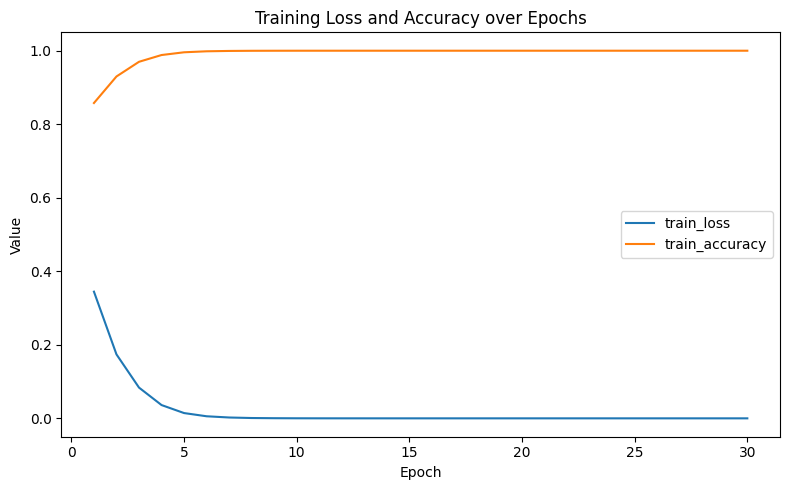

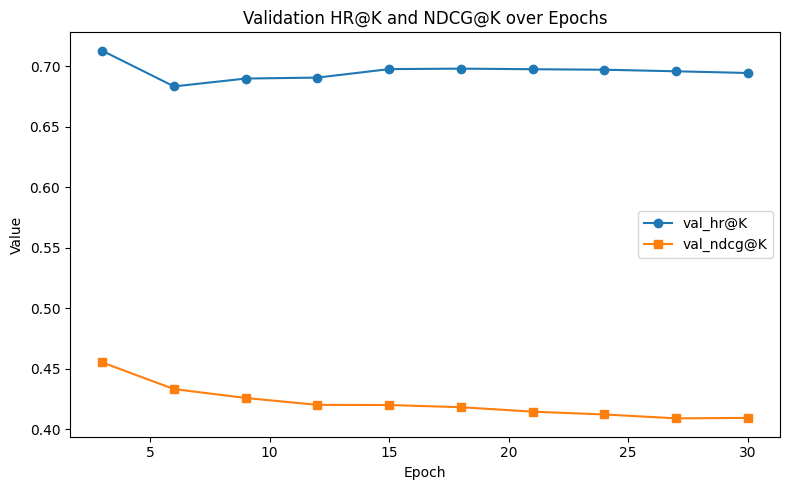

In [4]:
# ----- derived axes -----
val_hr = [0.7129, 0.6834, 0.6899, 0.6907, 0.6977, 0.6981, 0.6976, 0.6972, 0.6959, 0.6945]
val_ndcg = [0.45529333305893604, 0.4333015680069993, 0.4259624800841804, 0.4202700917165953, 0.42015216862967547, 0.4183238295150098, 0.41465737607257425, 0.4123217986785753, 0.40913119270049214, 0.4094813157537882]
train_loss_hist=  [0.34456688165664673, 0.17394113540649414, 0.08363743126392365, 0.036136843264102936, 0.014355571009218693, 0.00562362652271986, 0.0022968726698309183, 0.0008757629548199475, 0.0003738935920409858, 0.0001441263739252463, 5.6454802688676864e-05, 1.9136154151055962e-05, 4.908775281364797e-06, 9.429911074221309e-07, 2.1151828377696802e-07, 8.977119136943656e-08, 5.829540228319274e-08, 4.3680032035808836e-08, 3.49862752102581e-08, 2.9192143813361326e-08, 2.5049791574360825e-08, 2.193671022610033e-08, 1.950792061222728e-08, 1.7561536225230157e-08, 1.5967936306537922e-08, 1.4637092426994514e-08, 1.3509993124216635e-08, 1.2544608019027237e-08, 1.1706084102058867e-08, 1.0972007302711972e-08]
train_pairacc_hist = [0.8577319383621216, 0.9299376606941223, 0.9698587656021118, 0.9882628321647644, 0.9957237839698792, 0.9984263181686401, 0.9993864893913269, 0.999790370464325, 0.9999179840087891, 0.999970018863678, 0.9999899864196777, 0.9999964833259583, 0.9999994039535522, 0.9999997019767761, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]

EPOCHS = len(train_loss_hist)
epochs = list(range(1, EPOCHS + 1))
val_epochs = list(range(3, 3*len(val_hr) + 1, 3))  # [3,6,...,30]

# ----- Training curves (one axis) -----
plt.figure(figsize=(8,5))
plt.plot(epochs, train_loss_hist, label='train_loss')
plt.plot(epochs, train_pairacc_hist, label='train_accuracy')
plt.xlabel('Epoch'); plt.ylabel('Value'); plt.title('Training Loss and Accuracy over Epochs')
plt.legend(); plt.tight_layout()
plt.show()

# ----- Validation HR@K and NDCG@K every 3 epochs -----
plt.figure(figsize=(8,5))
plt.plot(val_epochs, val_hr, marker='o', label='val_hr@K')
plt.plot(val_epochs, val_ndcg, marker='s', label='val_ndcg@K')
plt.xlabel('Epoch'); plt.ylabel('Value'); plt.title('Validation HR@K and NDCG@K over Epochs')
plt.legend(); plt.tight_layout()
plt.show()

K- analysis for GMF on Yelp

In [7]:
import numpy as np
import tensorflow as tf

# ---- Build interaction matrix from TRAIN_CV and align to full id space ----
val_inter_mat = (
    train_df.assign(interaction=1)
            .pivot_table(index='user_id', columns='item_id',
                         values='interaction', fill_value=0)
)

# align so pivot indices == full [0..num_users-1] / [0..num_items-1]
val_inter_mat = val_inter_mat.reindex(index=np.arange(num_users),
                                      columns=np.arange(num_items),
                                      fill_value=0)
val_inter_arr = val_inter_mat.values

# -----------------------------
# Hyperparameters (GMF)
# -----------------------------
EPOCHS      = 30
BATCH_SIZE  = 256
K_val       = 10         # K for validation
emb_size    = 64
learning_rate = 0.001

val_hr = []
val_ndcg = []
train_loss_hist = []
train_acc_hist  = []     # binary accuracy

best = {'ndcg': -1.0, 'hr': 0.0, 'epoch': -1, 'weights': None}

# -----------------------------
# Build GMF model
# -----------------------------
gmf_model = build_GMF(
    num_users=num_users,
    num_items=num_items,
    learning_rate=learning_rate,
    emb_size=emb_size
)

# OPTIONAL: recompile with binary_accuracy to match logging
gmf_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate),
    loss=tf.keras.losses.BinaryCrossentropy(from_logits=False),
    metrics=['binary_accuracy']
)

# -----------------------------
# Epoch loop with periodic validation
# -----------------------------
for ep in range(1, EPOCHS + 1):
    print(f"\n=== GMF Epoch {ep}/{EPOCHS} ===")
    
    hist = gmf_model.fit(
        x=[user_input_train, item_input_train],
        y=labels_train,
        batch_size=BATCH_SIZE,
        epochs=1,
        shuffle=True,
        verbose=1
    )
    
    # log training loss / accuracy
    train_loss_hist.append(float(hist.history['loss'][0]))
    if 'binary_accuracy' in hist.history:
        train_acc_hist.append(float(hist.history['binary_accuracy'][0]))
    elif 'accuracy' in hist.history:
        train_acc_hist.append(float(hist.history['accuracy'][0]))
    else:
        train_acc_hist.append(np.nan)
    
    # every 3 epochs: full validation HR/NDCG at K_val
    if ep % 3 == 0:
        hr, ndcg = eval_hr_ndcg(
            val_inter_mat,     # interaction_matrix (known positives)
            val_inter_arr,     # dense array version
            val_df,            # VAL df (one held-out positive per user)
            gmf_model,         # scoring model
            number_of_rec_items=K_val,
            max_test_size=10_000,
            neg_sample_size=100
        )
        val_hr.append(hr)
        val_ndcg.append(ndcg)
        
        print(f"[VAL] GMF Epoch {ep}: HR@{K_val}={hr:.4f}, NDCG@{K_val}={ndcg:.4f}")
        
        # track best by NDCG
        if ndcg > best['ndcg']:
            best['ndcg'] = ndcg
            best['hr'] = hr
            best['epoch'] = ep
            best['weights'] = gmf_model.get_weights()
            print(f"New best GMF epoch: {ep} (NDCG={ndcg:.4f}, HR={hr:.4f})")

print("GMF VAL HR history:", val_hr)
print("GMF VAL NDCG history:", val_ndcg)
print("GMF Train loss history:", train_loss_hist)
print("GMF Train acc history:", train_acc_hist)


I0000 00:00:1765194024.271271      47 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 15513 MB memory:  -> device: 0, name: Tesla P100-PCIE-16GB, pci bus id: 0000:00:04.0, compute capability: 6.0



=== GMF Epoch 1/30 ===


I0000 00:00:1765194026.904624     108 service.cc:148] XLA service 0x7e18e0003ba0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1765194026.906304     108 service.cc:156]   StreamExecutor device (0): Tesla P100-PCIE-16GB, Compute Capability 6.0
I0000 00:00:1765194027.119728     108 cuda_dnn.cc:529] Loaded cuDNN version 90300


   74/13288 ━━━━━━━━━━━━━━━━━━━━ 27s 2ms/step - binary_accuracy: 0.7769 - loss: 0.6878

I0000 00:00:1765194027.594939     108 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


13288/13288 ━━━━━━━━━━━━━━━━━━━━ 29s 2ms/step - binary_accuracy: 0.8194 - loss: 0.4752

=== GMF Epoch 2/30 ===
13288/13288 ━━━━━━━━━━━━━━━━━━━━ 27s 2ms/step - binary_accuracy: 0.9132 - loss: 0.2130

=== GMF Epoch 3/30 ===
13288/13288 ━━━━━━━━━━━━━━━━━━━━ 27s 2ms/step - binary_accuracy: 0.9532 - loss: 0.1242
HR@10 = 0.7235
NDCG@10 = 0.4616
[VAL] GMF Epoch 3: HR@10=0.7235, NDCG@10=0.4616
New best GMF epoch: 3 (NDCG=0.4616, HR=0.7235)

=== GMF Epoch 4/30 ===
13288/13288 ━━━━━━━━━━━━━━━━━━━━ 27s 2ms/step - binary_accuracy: 0.9777 - loss: 0.0665

=== GMF Epoch 5/30 ===
13288/13288 ━━━━━━━━━━━━━━━━━━━━ 27s 2ms/step - binary_accuracy: 0.9905 - loss: 0.0317

=== GMF Epoch 6/30 ===
13288/13288 ━━━━━━━━━━━━━━━━━━━━ 27s 2ms/step - binary_accuracy: 0.9965 - loss: 0.0133
HR@10 = 0.6875
NDCG@10 = 0.4315
[VAL] GMF Epoch 6: HR@10=0.6875, NDCG@10=0.4315

=== GMF Epoch 7/30 ===
13288/13288 ━━━━━━━━━━━━━━━━━━━━ 27s 2ms/step - binary_accuracy: 0.9987 - loss: 0.0053

=== GMF Epoch 8/30 ===
13288/13288 ━━━━

In [8]:
# Restore best weights if we have them
if best['weights'] is not None:
    gmf_model.set_weights(best['weights'])
    print(f"Loaded best GMF weights from epoch {best['epoch']}")
else:
    print("Warning: no best GMF checkpoint stored, using last-epoch weights")

for K_test in [5, 10, 20]:
    hr_t, ndcg_t = eval_hr_ndcg(
        val_inter_mat,          # interaction_matrix (same as for validation)
        val_inter_arr,
        test_df,                # TEST df (leave-one-out per user)
        gmf_model,
        number_of_rec_items=K_test,
        max_test_size=10_000,
        neg_sample_size=99      # 1 positive + up to 99 negatives
    )
    print(f"[GMF TEST @ best epoch {best['epoch']}] "
          f"HR@{K_test}={hr_t:.4f}  NDCG@{K_test}={ndcg_t:.4f}")




Loaded best GMF weights from epoch 3
HR@5 = 0.5345
NDCG@5 = 0.3800
[GMF TEST @ best epoch 3] HR@5=0.5345  NDCG@5=0.3800
HR@10 = 0.6775
NDCG@10 = 0.4284
[GMF TEST @ best epoch 3] HR@10=0.6775  NDCG@10=0.4284
HR@20 = 0.8039
NDCG@20 = 0.4578
[GMF TEST @ best epoch 3] HR@20=0.8039  NDCG@20=0.4578


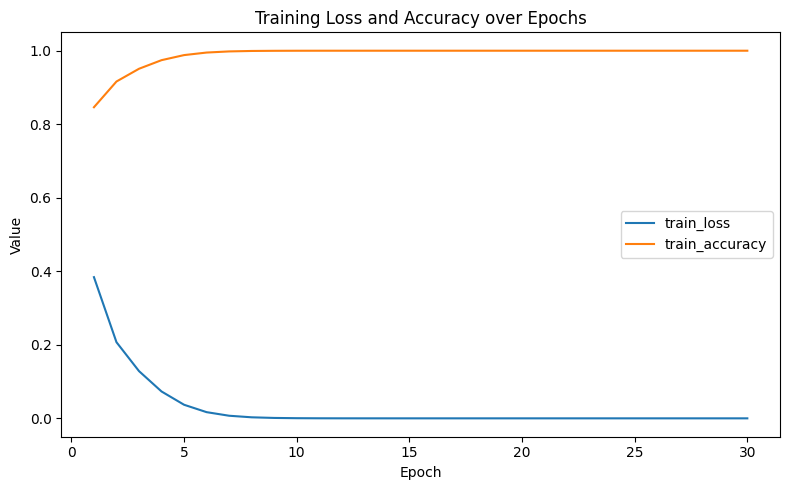

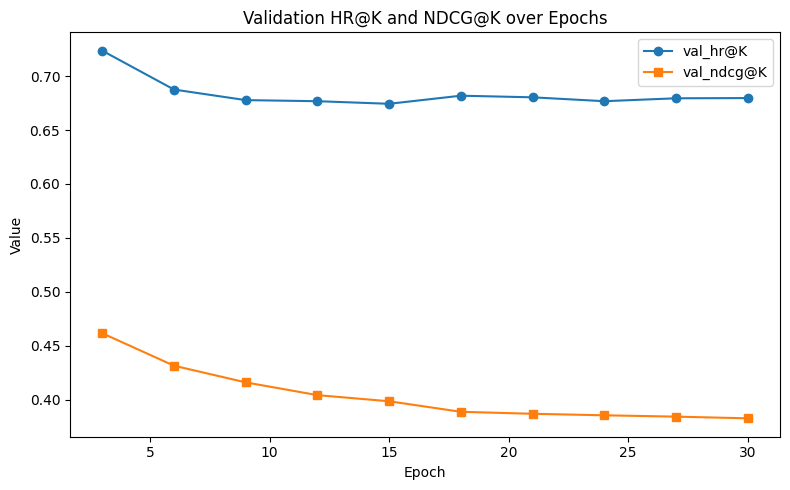

In [10]:
EPOCHS = len(train_loss_hist)
epochs = list(range(1, EPOCHS + 1))
val_epochs = list(range(3, 3*len(val_hr) + 1, 3))  # [3,6,...,30]

# ----- Training curves (one axis) -----
plt.figure(figsize=(8,5))
plt.plot(epochs, train_loss_hist, label='train_loss')
plt.plot(epochs, train_acc_hist, label='train_accuracy')
plt.xlabel('Epoch'); plt.ylabel('Value'); plt.title('Training Loss and Accuracy over Epochs')
plt.legend(); plt.tight_layout()
plt.show()

# ----- Validation HR@K and NDCG@K every 3 epochs -----
plt.figure(figsize=(8,5))
plt.plot(val_epochs, val_hr, marker='o', label='val_hr@K')
plt.plot(val_epochs, val_ndcg, marker='s', label='val_ndcg@K')
plt.xlabel('Epoch'); plt.ylabel('Value'); plt.title('Validation HR@K and NDCG@K over Epochs')
plt.legend(); plt.tight_layout()
plt.show()

MLP K-analysis 

In [1]:

#Plotting training and Validation accuracy
def plot_accuracy(history):
    plt.figure()
    acc_key = 'accuracy' if 'accuracy' in history.history else 'binary_accuracy'
    val_acc_key = 'val_' + acc_key

    plt.plot(history.history[acc_key], label='Train Accuracy')
    if val_acc_key in history.history:
        plt.plot(history.history[val_acc_key], label='Validation Accuracy')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend()



#HR (hit ratio)
def HR(ranked_predicted_list, true_test_item, number_of_rec_items = 10):
    top_rec_items = ranked_predicted_list[:number_of_rec_items]
    item_ids = [item_id for item_id, _ in top_rec_items]
    if true_test_item in item_ids:
        return 1.0
    else:
        return 0.0
#Normalized Discounted Cumulative Gain (NDCG) 


def NDCG(ranked_predicted_list, true_test_item, number_of_rec_items):
    top_rec_items = ranked_predicted_list[:number_of_rec_items]
    item_ids = [item_id for item_id, _ in top_rec_items]
    for rank, item_id in enumerate(item_ids):
        if item_id == true_test_item:
            return 1.0/math.log2((rank+1) +1)
    return 0



#Get the predictions


#Evaluation using HR
def eval_hr_ndcg(
    interaction_matrix,
    interaction_array,
    test_df,
    model,
    number_of_rec_items,
    max_test_size,
    neg_sample_size=100,
):
    user_index_list = interaction_matrix.index.tolist()
    item_index_list = interaction_matrix.columns.tolist()

    user2pivot = {uid: idx for idx, uid in enumerate(user_index_list)}
    item2pivot = {iid: idx for idx, iid in enumerate(item_index_list)}

    # Build user -> set(positive items) from interaction_array
    user_item_dict = defaultdict(set)
    n_users = interaction_array.shape[0]
    for user in range(n_users):
        item_positions = np.where(interaction_array[user] == 1)[0]
        user_item_dict[user] = set(item_positions)

    all_items = list(range(num_items))  # uses global num_items

    users = test_df['user_id'].values
    items = test_df['item_id'].values

    num_hits = 0.0
    num_test = 0.0
    sum_ndcg = 0.0

    for df_user, df_item in zip(users, items):
        # skip users/items not in pivot
        if (df_user not in user2pivot) or (df_item not in item2pivot):
            continue

        user_idx = user2pivot[df_user]
        item_idx = item2pivot[df_item]

        items_interacted = user_item_dict[user_idx]
        possible_sample_of_neg = list(set(all_items) - items_interacted - {item_idx})

        if len(possible_sample_of_neg) == 0:
            continue

        # sample min(neg_sample_size, len(candidates)) negatives
        n_neg = min(neg_sample_size, len(possible_sample_of_neg))
        negative_sample = random.sample(possible_sample_of_neg, n_neg)

        test_sample_per_user = negative_sample + [item_idx]

        # model predictions
        array_of_users = np.full(len(test_sample_per_user), user_idx, dtype='int32')
        array_of_items = np.array(test_sample_per_user, dtype='int32')

        predictions = model.predict([array_of_users, array_of_items], verbose=0).flatten()
        test_sample_per_user_predictions = list(zip(test_sample_per_user, predictions))
        ranked_predicted_list = sorted(
            test_sample_per_user_predictions,
            key=lambda x: x[1],
            reverse=True
        )

        hit = HR(ranked_predicted_list, item_idx, number_of_rec_items=number_of_rec_items)
        ndcg_val = NDCG(ranked_predicted_list, item_idx, number_of_rec_items)

        sum_ndcg += ndcg_val
        num_hits += hit
        num_test += 1

        if max_test_size <= num_test:
            break

    if num_test == 0:
        average_num_hits = 0.0
        ndcg_k = 0.0
    else:
        average_num_hits = num_hits / num_test
        ndcg_k = sum_ndcg / num_test

    print(f"HR@{number_of_rec_items} = {average_num_hits:.4f}")
    print(f"NDCG@{number_of_rec_items} = {ndcg_k:.4f}")
    return average_num_hits, ndcg_k
    
   
    
#Get weights from pretrained models
def get_weights(gmf_model, mlp_model,neumf_model,hidden_units,alpha):
    
    #From GMF (emb layer):
    gmf_user_emb = gmf_model.get_layer('gmf_user_embedding').get_weights()
    gmf_item_emb = gmf_model.get_layer('gmf_item_embedding').get_weights()

    #From GMF (output layer)
    gmf_output_weights = gmf_model.get_layer('outputs').get_weights()  
        
    #To NeuMF from GMF
    #(Emb)
    neumf_model.get_layer('gmf_user_embedding').set_weights(gmf_user_emb)
    neumf_model.get_layer('gmf_item_embedding').set_weights(gmf_item_emb)

    #(Output)

    #neumf_model.get_layer('gmf_outputs').set_weights(gmf_output_weights)

    #From MLP (emb layer)
    mlp_user_emb = mlp_model.get_layer('user_embedding').get_weights()
    mlp_item_emb = mlp_model.get_layer('item_embedding').get_weights()
    #Fron MLP (layers)
    
    #From MLP (output layer)
    mlp_output_weights = mlp_model.get_layer('outputs').get_weights()  

    #To NeuMF from GMF
    #(Emb)
    neumf_model.get_layer('mlp_user_embedding').set_weights(mlp_user_emb)
    neumf_model.get_layer('mlp_item_embedding').set_weights(mlp_item_emb)
    #(Layers)
    for idx, _ in enumerate(hidden_units):
        mlp_layer_weights = mlp_model.get_layer(f"hidden_{idx}").get_weights()
        neumf_model.get_layer(f"mlp_hidden_{idx}").set_weights(mlp_layer_weights)
    #(Output)
    #neumf_model.get_layer('mlp_outputs').set_weights(mlp_output_weights)

    #Concatenate weights:
    Wg, bg = gmf_output_weights
    Wm, bm = mlp_output_weights
    W_final = np.concatenate([alpha * Wg, (1 - alpha) * Wm], axis=0)
    b_final = alpha * bg + (1 - alpha) * bm
    #Add concatenated weights and biases to the NEUMF
    neumf_model.get_layer('neumf_outputs').set_weights([W_final, b_final])
    
    print("Weights added")
    

    
    





#Used libraries

import numpy as np
from tensorflow.keras.layers import (
    Input, Embedding, Flatten, Multiply, 
    Dense, Concatenate, Activation
)
import tensorflow as tf

from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
import pandas as pd
import numpy as np
from sklearn.preprocessing import LabelEncoder
import matplotlib.pyplot as plt
from collections import defaultdict
import random
import math
import pandas as pd
import numpy as np
from sklearn.preprocessing import LabelEncoder
import os
import sys

def read_yelp_rating_file(file_path):
    # Check if the file exists
    if not os.path.exists(file_path):
        print(f"Error: File '{file_path}' does not exist.")
        sys.exit(1)

    try:
        # Read the file into a DataFrame (auto-detects whitespace or tab)
        df = pd.read_csv(
            file_path,
            sep=r'\s+',            # handles both tabs and spaces
            header=None,
            names=['user_id', 'item_id', 'rating', 'timestamp'],
            engine='python'        # allows regex separator
        )

        # Display basic information about the DataFrame
        print("✅ Data successfully loaded.\n")
        print("DataFrame Info:")
        print(df.info())
        print("\nFirst 5 rows of the DataFrame:")
        print(df.head())

        return df

    except Exception as e:
        print(f" Error reading file '{file_path}': {e}")
        sys.exit(1)

yelp_file_path = f"{DATA_DIR}/yelp.rating"
yelp_df = read_yelp_rating_file(yelp_file_path)
df = yelp_df
# -----------------------------
# 1. Basic sanity check
# -----------------------------
user_counts = df.groupby("user_id").size()
print("Minimum number of ratings per user:", user_counts.min())

# -----------------------------
# 2. Leave-one-out split: train / test
# -----------------------------
# Sort by user, then timestamp
df = df.sort_values(['user_id', 'timestamp'])

train_list = []
test_list  = []

for user_id, group in df.groupby('user_id'):
    user_history = group.values  # or group.to_numpy()

    # Last interaction = test
    test_interaction = user_history[-1]
    # All previous = train
    train_interactions = user_history[:-1]

    for row in train_interactions:
        train_list.append(row)
    test_list.append(test_interaction)

train_df = pd.DataFrame(train_list, columns=df.columns).reset_index(drop=True)
test_df  = pd.DataFrame(test_list,  columns=df.columns).reset_index(drop=True)

# -----------------------------
# 3. Validation split from train (second last per user)
# -----------------------------
train_df = train_df.sort_values(['user_id', 'timestamp'])
val_df = train_df.groupby('user_id').tail(1).copy()      # 1 row per user
train_df_cv = train_df.drop(val_df.index).copy()         # remaining as train

train_df = train_df_cv.reset_index(drop=True)
val_df   = val_df.reset_index(drop=True)

print("Training size:", len(train_df))
print("Validation size:", len(val_df))
print("Testing size: ", len(test_df))

# -----------------------------
# 4. Label-encode user/item on TRAIN + VAL + TEST
# -----------------------------
ue, ie = LabelEncoder(), LabelEncoder()

all_ids = pd.concat([
    train_df[['user_id', 'item_id']],
    val_df[['user_id', 'item_id']],
    test_df[['user_id', 'item_id']]
], axis=0)

ue.fit(all_ids['user_id'])
ie.fit(all_ids['item_id'])

train_df['user_id'] = ue.transform(train_df['user_id'])
train_df['item_id'] = ie.transform(train_df['item_id'])
val_df['user_id']   = ue.transform(val_df['user_id'])
val_df['item_id']   = ie.transform(val_df['item_id'])
test_df['user_id']  = ue.transform(test_df['user_id'])
test_df['item_id']  = ie.transform(test_df['item_id'])

num_users = len(ue.classes_)
num_items = len(ie.classes_)

# -----------------------------
# 5. Build per-user positive sets from TRAIN ONLY
#    (to avoid leakage when sampling negatives)
# -----------------------------
user_pos = train_df.groupby('user_id')['item_id'].apply(set).to_dict()
all_items = np.arange(num_items, dtype=np.int32)

# -----------------------------
# 6. Negative sampling for NeuMF training
# -----------------------------
num_neg = 4  # how many negatives per positive

user_input = []
item_input = []
labels     = []

# Go through each positive in the TRAIN set
for row in train_df.itertuples(index=False):
    u = row.user_id
    i = row.item_id

    # Positive instance
    user_input.append(u)
    item_input.append(i)
    labels.append(1)

    # Negative instances
    pos_items = user_pos[u]
    for _ in range(num_neg):
        j = np.random.randint(num_items)
        # resample until we get an item not interacted with by this user
        while j in pos_items:
            j = np.random.randint(num_items)
        user_input.append(u)
        item_input.append(j)
        labels.append(0)

user_input_train = np.array(user_input, dtype=np.int32)
item_input_train = np.array(item_input, dtype=np.int32)
labels_train     = np.array(labels,     dtype=np.float32)

print("Train triplets (pos+neg):", len(labels_train))
print("Num users:", num_users, "Num items:", num_items)


2025-12-08 15:10:46.648467: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1765206646.828173      47 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1765206646.883012      47 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

✅ Data successfully loaded.

DataFrame Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731671 entries, 0 to 731670
Data columns (total 4 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   user_id    731671 non-null  int64  
 1   item_id    731671 non-null  int64  
 2   rating     731671 non-null  float64
 3   timestamp  731671 non-null  int64  
dtypes: float64(1), int64(3)
memory usage: 22.3 MB
None

First 5 rows of the DataFrame:
   user_id  item_id  rating   timestamp
0        0        0     4.0  1329148800
1        0        0     4.0  1337011200
2        0        1     4.0  1335888000
3        0        2     4.0  1379260800
4        0        3     2.0  1367856000
Minimum number of ratings per user: 10
Training size: 680317
Validation size: 25677
Testing size:  25677
Train triplets (pos+neg): 3401585
Num users: 25677 Num items: 25815


In [3]:
#GMF model

def build_GMF(num_users, num_items, learning_rate,emb_size):
    user_input = Input(shape=(1,), name='user_input')
    item_input = Input(shape=(1,), name='item_input')
    
    user_embedding = Embedding(
        input_dim=num_users, 
        output_dim=emb_size, 
        name='gmf_user_embedding'
    )
    item_embedding = Embedding(
        input_dim=num_items,
        output_dim=emb_size,
        name='gmf_item_embedding'
    )
    
    user_latent = Flatten()(user_embedding(user_input))
    item_latent = Flatten()(item_embedding(item_input))
    gmf_vector = Multiply()([user_latent, item_latent])
    
    outputs = Dense(1, activation='sigmoid', name='outputs')(gmf_vector)
    model = Model(
        inputs=[user_input,item_input],
        outputs=outputs
    )
    
    return model

#MPL model
def build_MLP(num_users, num_items, emb_size, hidden_units, learning_rate):
    user_input = Input(shape=(1,), name='user_input')   
    item_input = Input(shape=(1,), name='item_input')   

    user_embedding = Embedding(
        input_dim=num_users,
        output_dim=emb_size,
        name='user_embedding'
    )(user_input)
    user_embedding = Flatten()(user_embedding)

    item_embedding = Embedding(
        input_dim=num_items,
        output_dim=emb_size,
        name='item_embedding'
    )(item_input)
    item_embedding = Flatten()(item_embedding)

    concat_vec = Concatenate(axis=1)([user_embedding, item_embedding])
    x = concat_vec
    
    for idx, units in enumerate(hidden_units):
        x = Dense(units, activation='relu', name=f"hidden_{idx}")(x)
        
    outputs = Dense(1, activation='sigmoid', name='outputs')(x)
    
    model = Model(
        inputs=[user_input, item_input],
        outputs=outputs
    )
    return model


#NeuMF model

def build_NEUMF(
    num_users,
    num_items,
    latent_dim,      # currently unused, kept for API compatibility
    hidden_units,
    emb_size,
    learning_rate,
    alpha=0.5        # currently unused here; used in get_weights
):
    user_input = Input(shape=(1,), name='user_input')   
    item_input = Input(shape=(1,), name='item_input') 

    # ----- MLP branch -----
    mlp_user_embedding = Embedding(
        input_dim=num_users,
        output_dim=emb_size,
        name='mlp_user_embedding'
    )(user_input)
    mlp_user_embedding = Flatten()(mlp_user_embedding)

    mlp_item_embedding = Embedding(
        input_dim=num_items,
        output_dim=emb_size,
        name='mlp_item_embedding'
    )(item_input)
    mlp_item_embedding = Flatten()(mlp_item_embedding)

    mlp_concat_vec = Concatenate(axis=1)([mlp_user_embedding, mlp_item_embedding])
    x = mlp_concat_vec
    for idx, units in enumerate(hidden_units):
        x = Dense(units, activation='relu', name=f"mlp_hidden_{idx}")(x)
    mlp_vector = x

    # ----- GMF branch -----
    gmf_user_embedding = Embedding(
        input_dim=num_users, 
        output_dim=emb_size, 
        name='gmf_user_embedding'
    )
    gmf_item_embedding = Embedding(
        input_dim=num_items,
        output_dim=emb_size,
        name='gmf_item_embedding'
    )
    gmf_user_latent = Flatten()(gmf_user_embedding(user_input))
    gmf_item_latent = Flatten()(gmf_item_embedding(item_input))
    gmf_vector = Multiply()([gmf_user_latent, gmf_item_latent])

    # ----- NeuMF fusion -----
    neumf_concat = Concatenate(axis=1)([mlp_vector, gmf_vector])
    neumf_outputs = Dense(1, activation='sigmoid', name='neumf_outputs')(neumf_concat)

    model = Model(
        inputs=[user_input, item_input],
        outputs=neumf_outputs
    )
    # DO NOT compile here; you compile outside
    return model


In [4]:
import numpy as np
import tensorflow as tf

# ---- Build interaction matrix from TRAIN_CV and align to full id space ----
val_inter_mat = (
    train_df.assign(interaction=1)
            .pivot_table(index='user_id', columns='item_id',
                         values='interaction', fill_value=0)
)

# align so pivot indices == full [0..num_users-1] / [0..num_items-1]
val_inter_mat = val_inter_mat.reindex(index=np.arange(num_users),
                                      columns=np.arange(num_items),
                                      fill_value=0)
val_inter_arr = val_inter_mat.values

# -----------------------------
# Hyperparameters (MLP)
# -----------------------------
EPOCHS       = 30
BATCH_SIZE   = 256
K_val        = 10          # K for validation
emb_size     = 64
hidden_units = [32, 16, 8] # or whatever you used before
learning_rate = 0.001

mlp_val_hr = []
mlp_val_ndcg = []
mlp_train_loss_hist = []
mlp_train_acc_hist  = []   # binary accuracy

mlp_best = {'ndcg': -1.0, 'hr': 0.0, 'epoch': -1, 'weights': None}

# -----------------------------
# Build & compile MLP model
# -----------------------------
mlp_model = build_MLP(
    num_users=num_users,
    num_items=num_items,
    emb_size=emb_size,
    hidden_units=hidden_units,
    learning_rate=learning_rate
)

mlp_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate),
    loss=tf.keras.losses.BinaryCrossentropy(from_logits=False),
    metrics=['binary_accuracy']
)

print("Sanity check (MLP):")
print("train_df shape:", train_df.shape)
print("num_users, num_items:", num_users, num_items)
print("train triples:", len(labels_train))
print("EPOCHS:", EPOCHS)

# -----------------------------
# Epoch loop with periodic validation
# -----------------------------
for ep in range(1, EPOCHS + 1):
    print(f"\n=== MLP Epoch {ep}/{EPOCHS} ===")
    
    hist = mlp_model.fit(
        x=[user_input_train, item_input_train],
        y=labels_train,
        batch_size=BATCH_SIZE,
        epochs=1,
        shuffle=True,
        verbose=1
    )
    
    # log training loss / accuracy
    mlp_train_loss_hist.append(float(hist.history['loss'][0]))
    if 'binary_accuracy' in hist.history:
        mlp_train_acc_hist.append(float(hist.history['binary_accuracy'][0]))
    elif 'accuracy' in hist.history:
        mlp_train_acc_hist.append(float(hist.history['accuracy'][0]))
    else:
        mlp_train_acc_hist.append(np.nan)
    
    # every 3 epochs: full validation HR/NDCG at K_val
    if ep % 3 == 0:
        hr, ndcg = eval_hr_ndcg(
            val_inter_mat,     # interaction_matrix (known positives)
            val_inter_arr,     # dense array version
            val_df,            # VAL df (one held-out positive per user)
            mlp_model,         # scoring model
            number_of_rec_items=K_val,
            max_test_size=10_000,
            neg_sample_size=100
        )
        mlp_val_hr.append(hr)
        mlp_val_ndcg.append(ndcg)
        
        print(f"[VAL] MLP Epoch {ep}: HR@{K_val}={hr:.4f}, NDCG@{K_val}={ndcg:.4f}")
        
        # track best by NDCG
        if ndcg > mlp_best['ndcg']:
            mlp_best['ndcg'] = ndcg
            mlp_best['hr'] = hr
            mlp_best['epoch'] = ep
            mlp_best['weights'] = mlp_model.get_weights()
            print(f"New best MLP epoch: {ep} (NDCG={ndcg:.4f}, HR={hr:.4f})")

print("MLP VAL HR history:", mlp_val_hr)
print("MLP VAL NDCG history:", mlp_val_ndcg)
print("MLP Train loss history:", mlp_train_loss_hist)
print("MLP Train acc history:", mlp_train_acc_hist)


I0000 00:00:1765206732.408723      47 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 15513 MB memory:  -> device: 0, name: Tesla P100-PCIE-16GB, pci bus id: 0000:00:04.0, compute capability: 6.0


Sanity check (MLP):
train_df shape: (680317, 4)
num_users, num_items: 25677 25815
train triples: 3401585
EPOCHS: 30

=== MLP Epoch 1/30 ===


I0000 00:00:1765206735.356702     112 service.cc:148] XLA service 0x7e01200056b0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1765206735.357222     112 service.cc:156]   StreamExecutor device (0): Tesla P100-PCIE-16GB, Compute Capability 6.0
I0000 00:00:1765206735.657536     112 cuda_dnn.cc:529] Loaded cuDNN version 90300


   69/13288 ━━━━━━━━━━━━━━━━━━━━ 29s 2ms/step - binary_accuracy: 0.7946 - loss: 0.6417

I0000 00:00:1765206736.517360     112 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


13288/13288 ━━━━━━━━━━━━━━━━━━━━ 33s 2ms/step - binary_accuracy: 0.8303 - loss: 0.4080

=== MLP Epoch 2/30 ===
13288/13288 ━━━━━━━━━━━━━━━━━━━━ 29s 2ms/step - binary_accuracy: 0.8805 - loss: 0.2672

=== MLP Epoch 3/30 ===
13288/13288 ━━━━━━━━━━━━━━━━━━━━ 29s 2ms/step - binary_accuracy: 0.8961 - loss: 0.2306
HR@10 = 0.6955
NDCG@10 = 0.4318
[VAL] MLP Epoch 3: HR@10=0.6955, NDCG@10=0.4318
New best MLP epoch: 3 (NDCG=0.4318, HR=0.6955)

=== MLP Epoch 4/30 ===
13288/13288 ━━━━━━━━━━━━━━━━━━━━ 30s 2ms/step - binary_accuracy: 0.9047 - loss: 0.2120

=== MLP Epoch 5/30 ===
13288/13288 ━━━━━━━━━━━━━━━━━━━━ 29s 2ms/step - binary_accuracy: 0.9123 - loss: 0.1973

=== MLP Epoch 6/30 ===
13288/13288 ━━━━━━━━━━━━━━━━━━━━ 29s 2ms/step - binary_accuracy: 0.9202 - loss: 0.1828
HR@10 = 0.7138
NDCG@10 = 0.4509
[VAL] MLP Epoch 6: HR@10=0.7138, NDCG@10=0.4509
New best MLP epoch: 6 (NDCG=0.4509, HR=0.7138)

=== MLP Epoch 7/30 ===
13288/13288 ━━━━━━━━━━━━━━━━━━━━ 29s 2ms/step - binary_accuracy: 0.9268 - loss: 

Loaded best MLP weights from epoch 6
HR@5 = 0.5195
NDCG@5 = 0.3688
[MLP TEST @ best epoch 6] HR@5=0.5195  NDCG@5=0.3688
HR@10 = 0.6787
NDCG@10 = 0.4224
[MLP TEST @ best epoch 6] HR@10=0.6787  NDCG@10=0.4224
HR@20 = 0.8162
NDCG@20 = 0.4558
[MLP TEST @ best epoch 6] HR@20=0.8162  NDCG@20=0.4558


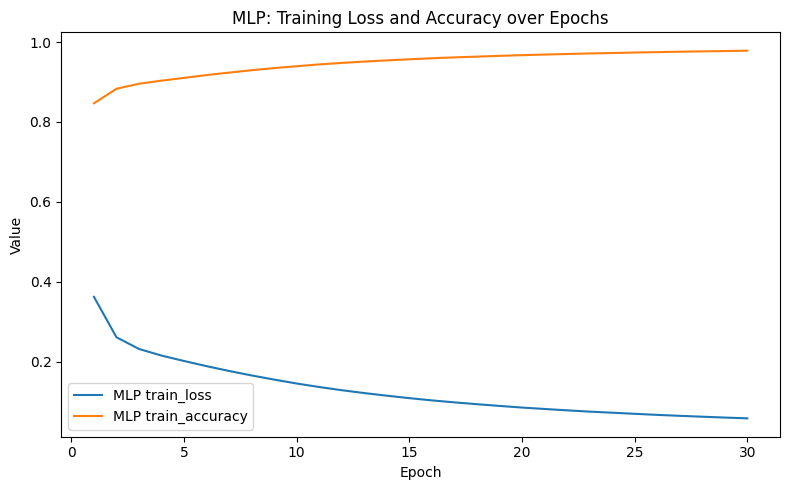

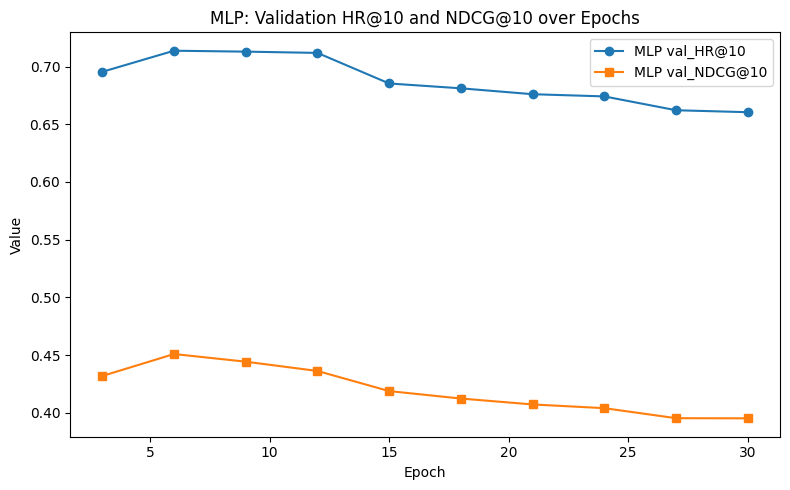

In [6]:
# ----- TEST: MLP on best checkpoint -----
if mlp_best['weights'] is not None:
    mlp_model.set_weights(mlp_best['weights'])
    print(f"Loaded best MLP weights from epoch {mlp_best['epoch']}")
else:
    print("Warning: no best MLP checkpoint stored, using last-epoch weights")

for K_test in [5, 10, 20]:
    hr_t, ndcg_t = eval_hr_ndcg(
        val_inter_mat,          # interaction_matrix (same as for validation)
        val_inter_arr,
        test_df,                # TEST df (leave-one-out per user)
        mlp_model,
        number_of_rec_items=K_test,
        max_test_size=10_000,
        neg_sample_size=99
    )
    print(
        f"[MLP TEST @ best epoch {mlp_best['epoch']}] "
        f"HR@{K_test}={hr_t:.4f}  NDCG@{K_test}={ndcg_t:.4f}"
    )

# ----- Plots -----
EPOCHS_MLP = len(mlp_train_loss_hist)
epochs_mlp = list(range(1, EPOCHS_MLP + 1))
val_epochs_mlp = list(range(3, 3 * len(mlp_val_hr) + 1, 3))

# Training curves
plt.figure(figsize=(8, 5))
plt.plot(epochs_mlp, mlp_train_loss_hist, label='MLP train_loss')
plt.plot(epochs_mlp, mlp_train_acc_hist, label='MLP train_accuracy')
plt.xlabel('Epoch')
plt.ylabel('Value')
plt.title('MLP: Training Loss and Accuracy over Epochs')
plt.legend()
plt.tight_layout()
plt.show()

# Validation HR@K and NDCG@K every 3 epochs
plt.figure(figsize=(8, 5))
plt.plot(val_epochs_mlp, mlp_val_hr, marker='o', label=f'MLP val_HR@{K_val}')
plt.plot(val_epochs_mlp, mlp_val_ndcg, marker='s', label=f'MLP val_NDCG@{K_val}')
plt.xlabel('Epoch')
plt.ylabel('Value')
plt.title(f'MLP: Validation HR@{K_val} and NDCG@{K_val} over Epochs')
plt.legend()
plt.tight_layout()
plt.show()


NeuMF w prereained

In [2]:

#Plotting training and Validation accuracy
def plot_accuracy(history):
    plt.figure()
    acc_key = 'accuracy' if 'accuracy' in history.history else 'binary_accuracy'
    val_acc_key = 'val_' + acc_key

    plt.plot(history.history[acc_key], label='Train Accuracy')
    if val_acc_key in history.history:
        plt.plot(history.history[val_acc_key], label='Validation Accuracy')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend()



#HR (hit ratio)
def HR(ranked_predicted_list, true_test_item, number_of_rec_items = 10):
    top_rec_items = ranked_predicted_list[:number_of_rec_items]
    item_ids = [item_id for item_id, _ in top_rec_items]
    if true_test_item in item_ids:
        return 1.0
    else:
        return 0.0
#Normalized Discounted Cumulative Gain (NDCG) 


def NDCG(ranked_predicted_list, true_test_item, number_of_rec_items):
    top_rec_items = ranked_predicted_list[:number_of_rec_items]
    item_ids = [item_id for item_id, _ in top_rec_items]
    for rank, item_id in enumerate(item_ids):
        if item_id == true_test_item:
            return 1.0/math.log2((rank+1) +1)
    return 0



#Get the predictions


#Evaluation using HR
def eval_hr_ndcg(
    interaction_matrix,
    interaction_array,
    test_df,
    model,
    number_of_rec_items,
    max_test_size,
    neg_sample_size=100,
):
    user_index_list = interaction_matrix.index.tolist()
    item_index_list = interaction_matrix.columns.tolist()

    user2pivot = {uid: idx for idx, uid in enumerate(user_index_list)}
    item2pivot = {iid: idx for idx, iid in enumerate(item_index_list)}

    # Build user -> set(positive items) from interaction_array
    user_item_dict = defaultdict(set)
    n_users = interaction_array.shape[0]
    for user in range(n_users):
        item_positions = np.where(interaction_array[user] == 1)[0]
        user_item_dict[user] = set(item_positions)

    all_items = list(range(num_items))  # uses global num_items

    users = test_df['user_id'].values
    items = test_df['item_id'].values

    num_hits = 0.0
    num_test = 0.0
    sum_ndcg = 0.0

    for df_user, df_item in zip(users, items):
        # skip users/items not in pivot
        if (df_user not in user2pivot) or (df_item not in item2pivot):
            continue

        user_idx = user2pivot[df_user]
        item_idx = item2pivot[df_item]

        items_interacted = user_item_dict[user_idx]
        possible_sample_of_neg = list(set(all_items) - items_interacted - {item_idx})

        if len(possible_sample_of_neg) == 0:
            continue

        # sample min(neg_sample_size, len(candidates)) negatives
        n_neg = min(neg_sample_size, len(possible_sample_of_neg))
        negative_sample = random.sample(possible_sample_of_neg, n_neg)

        test_sample_per_user = negative_sample + [item_idx]

        # model predictions
        array_of_users = np.full(len(test_sample_per_user), user_idx, dtype='int32')
        array_of_items = np.array(test_sample_per_user, dtype='int32')

        predictions = model.predict([array_of_users, array_of_items], verbose=0).flatten()
        test_sample_per_user_predictions = list(zip(test_sample_per_user, predictions))
        ranked_predicted_list = sorted(
            test_sample_per_user_predictions,
            key=lambda x: x[1],
            reverse=True
        )

        hit = HR(ranked_predicted_list, item_idx, number_of_rec_items=number_of_rec_items)
        ndcg_val = NDCG(ranked_predicted_list, item_idx, number_of_rec_items)

        sum_ndcg += ndcg_val
        num_hits += hit
        num_test += 1

        if max_test_size <= num_test:
            break

    if num_test == 0:
        average_num_hits = 0.0
        ndcg_k = 0.0
    else:
        average_num_hits = num_hits / num_test
        ndcg_k = sum_ndcg / num_test

    print(f"HR@{number_of_rec_items} = {average_num_hits:.4f}")
    print(f"NDCG@{number_of_rec_items} = {ndcg_k:.4f}")
    return average_num_hits, ndcg_k
    
   
    
#Get weights from pretrained models
def get_weights(gmf_model, mlp_model,neumf_model,hidden_units,alpha):
    
    #From GMF (emb layer):
    gmf_user_emb = gmf_model.get_layer('gmf_user_embedding').get_weights()
    gmf_item_emb = gmf_model.get_layer('gmf_item_embedding').get_weights()

    #From GMF (output layer)
    gmf_output_weights = gmf_model.get_layer('outputs').get_weights()  
        
    #To NeuMF from GMF
    #(Emb)
    neumf_model.get_layer('gmf_user_embedding').set_weights(gmf_user_emb)
    neumf_model.get_layer('gmf_item_embedding').set_weights(gmf_item_emb)

    #(Output)

    #neumf_model.get_layer('gmf_outputs').set_weights(gmf_output_weights)

    #From MLP (emb layer)
    mlp_user_emb = mlp_model.get_layer('user_embedding').get_weights()
    mlp_item_emb = mlp_model.get_layer('item_embedding').get_weights()
    #Fron MLP (layers)
    
    #From MLP (output layer)
    mlp_output_weights = mlp_model.get_layer('outputs').get_weights()  

    #To NeuMF from GMF
    #(Emb)
    neumf_model.get_layer('mlp_user_embedding').set_weights(mlp_user_emb)
    neumf_model.get_layer('mlp_item_embedding').set_weights(mlp_item_emb)
    #(Layers)
    for idx, _ in enumerate(hidden_units):
        mlp_layer_weights = mlp_model.get_layer(f"hidden_{idx}").get_weights()
        neumf_model.get_layer(f"mlp_hidden_{idx}").set_weights(mlp_layer_weights)
    #(Output)
    #neumf_model.get_layer('mlp_outputs').set_weights(mlp_output_weights)

    #Concatenate weights:
    Wg, bg = gmf_output_weights
    Wm, bm = mlp_output_weights
    W_final = np.concatenate([alpha * Wg, (1 - alpha) * Wm], axis=0)
    b_final = alpha * bg + (1 - alpha) * bm
    #Add concatenated weights and biases to the NEUMF
    neumf_model.get_layer('neumf_outputs').set_weights([W_final, b_final])
    
    print("Weights added")
    

    
    





#Used libraries

import numpy as np
from tensorflow.keras.layers import (
    Input, Embedding, Flatten, Multiply, 
    Dense, Concatenate, Activation
)
import tensorflow as tf

from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
import pandas as pd
import numpy as np
from sklearn.preprocessing import LabelEncoder
import matplotlib.pyplot as plt
from collections import defaultdict
import random
import math
import pandas as pd
import numpy as np
from sklearn.preprocessing import LabelEncoder
import os
import sys

def read_yelp_rating_file(file_path):
    # Check if the file exists
    if not os.path.exists(file_path):
        print(f"Error: File '{file_path}' does not exist.")
        sys.exit(1)

    try:
        # Read the file into a DataFrame (auto-detects whitespace or tab)
        df = pd.read_csv(
            file_path,
            sep=r'\s+',            # handles both tabs and spaces
            header=None,
            names=['user_id', 'item_id', 'rating', 'timestamp'],
            engine='python'        # allows regex separator
        )

        # Display basic information about the DataFrame
        print("✅ Data successfully loaded.\n")
        print("DataFrame Info:")
        print(df.info())
        print("\nFirst 5 rows of the DataFrame:")
        print(df.head())

        return df

    except Exception as e:
        print(f" Error reading file '{file_path}': {e}")
        sys.exit(1)

yelp_file_path = f"{DATA_DIR}/yelp.rating"
yelp_df = read_yelp_rating_file(yelp_file_path)
df = yelp_df
# -----------------------------
# 1. Basic sanity check
# -----------------------------
user_counts = df.groupby("user_id").size()
print("Minimum number of ratings per user:", user_counts.min())

# -----------------------------
# 2. Leave-one-out split: train / test
# -----------------------------
# Sort by user, then timestamp
df = df.sort_values(['user_id', 'timestamp'])

train_list = []
test_list  = []

for user_id, group in df.groupby('user_id'):
    user_history = group.values  # or group.to_numpy()

    # Last interaction = test
    test_interaction = user_history[-1]
    # All previous = train
    train_interactions = user_history[:-1]

    for row in train_interactions:
        train_list.append(row)
    test_list.append(test_interaction)

train_df = pd.DataFrame(train_list, columns=df.columns).reset_index(drop=True)
test_df  = pd.DataFrame(test_list,  columns=df.columns).reset_index(drop=True)

# -----------------------------
# 3. Validation split from train (second last per user)
# -----------------------------
train_df = train_df.sort_values(['user_id', 'timestamp'])
val_df = train_df.groupby('user_id').tail(1).copy()      # 1 row per user
train_df_cv = train_df.drop(val_df.index).copy()         # remaining as train

train_df = train_df_cv.reset_index(drop=True)
val_df   = val_df.reset_index(drop=True)

print("Training size:", len(train_df))
print("Validation size:", len(val_df))
print("Testing size: ", len(test_df))

# -----------------------------
# 4. Label-encode user/item on TRAIN + VAL + TEST
# -----------------------------
ue, ie = LabelEncoder(), LabelEncoder()

all_ids = pd.concat([
    train_df[['user_id', 'item_id']],
    val_df[['user_id', 'item_id']],
    test_df[['user_id', 'item_id']]
], axis=0)

ue.fit(all_ids['user_id'])
ie.fit(all_ids['item_id'])

train_df['user_id'] = ue.transform(train_df['user_id'])
train_df['item_id'] = ie.transform(train_df['item_id'])
val_df['user_id']   = ue.transform(val_df['user_id'])
val_df['item_id']   = ie.transform(val_df['item_id'])
test_df['user_id']  = ue.transform(test_df['user_id'])
test_df['item_id']  = ie.transform(test_df['item_id'])

num_users = len(ue.classes_)
num_items = len(ie.classes_)

# -----------------------------
# 5. Build per-user positive sets from TRAIN ONLY
#    (to avoid leakage when sampling negatives)
# -----------------------------
user_pos = train_df.groupby('user_id')['item_id'].apply(set).to_dict()
all_items = np.arange(num_items, dtype=np.int32)

# -----------------------------
# 6. Negative sampling for NeuMF training
# -----------------------------
num_neg = 4  # how many negatives per positive

user_input = []
item_input = []
labels     = []

# Go through each positive in the TRAIN set
for row in train_df.itertuples(index=False):
    u = row.user_id
    i = row.item_id

    # Positive instance
    user_input.append(u)
    item_input.append(i)
    labels.append(1)

    # Negative instances
    pos_items = user_pos[u]
    for _ in range(num_neg):
        j = np.random.randint(num_items)
        # resample until we get an item not interacted with by this user
        while j in pos_items:
            j = np.random.randint(num_items)
        user_input.append(u)
        item_input.append(j)
        labels.append(0)

user_input_train = np.array(user_input, dtype=np.int32)
item_input_train = np.array(item_input, dtype=np.int32)
labels_train     = np.array(labels,     dtype=np.float32)

print("Train triplets (pos+neg):", len(labels_train))
print("Num users:", num_users, "Num items:", num_items)


2025-12-08 20:24:47.234465: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1765225487.402862 1918474 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1765225487.452444 1918474 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

✅ Data successfully loaded.

DataFrame Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731671 entries, 0 to 731670
Data columns (total 4 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   user_id    731671 non-null  int64  
 1   item_id    731671 non-null  int64  
 2   rating     731671 non-null  float64
 3   timestamp  731671 non-null  int64  
dtypes: float64(1), int64(3)
memory usage: 22.3 MB
None

First 5 rows of the DataFrame:
   user_id  item_id  rating   timestamp
0        0        0     4.0  1329148800
1        0        0     4.0  1337011200
2        0        1     4.0  1335888000
3        0        2     4.0  1379260800
4        0        3     2.0  1367856000
Minimum number of ratings per user: 10
Training size: 680317
Validation size: 25677
Testing size:  25677
Train triplets (pos+neg): 3401585
Num users: 25677 Num items: 25815


In [4]:
#GMF model

def build_GMF(num_users, num_items, learning_rate,emb_size):
    user_input = Input(shape=(1,), name='user_input')
    item_input = Input(shape=(1,), name='item_input')
    
    user_embedding = Embedding(
        input_dim=num_users, 
        output_dim=emb_size, 
        name='gmf_user_embedding'
    )
    item_embedding = Embedding(
        input_dim=num_items,
        output_dim=emb_size,
        name='gmf_item_embedding'
    )
    
    user_latent = Flatten()(user_embedding(user_input))
    item_latent = Flatten()(item_embedding(item_input))
    gmf_vector = Multiply()([user_latent, item_latent])
    
    outputs = Dense(1, activation='sigmoid', name='outputs')(gmf_vector)
    model = Model(
        inputs=[user_input,item_input],
        outputs=outputs
    )
    
    return model

#MPL model
def build_MLP(num_users, num_items, emb_size, hidden_units, learning_rate):
    user_input = Input(shape=(1,), name='user_input')   
    item_input = Input(shape=(1,), name='item_input')   

    user_embedding = Embedding(
        input_dim=num_users,
        output_dim=emb_size,
        name='user_embedding'
    )(user_input)
    user_embedding = Flatten()(user_embedding)

    item_embedding = Embedding(
        input_dim=num_items,
        output_dim=emb_size,
        name='item_embedding'
    )(item_input)
    item_embedding = Flatten()(item_embedding)

    concat_vec = Concatenate(axis=1)([user_embedding, item_embedding])
    x = concat_vec
    
    for idx, units in enumerate(hidden_units):
        x = Dense(units, activation='relu', name=f"hidden_{idx}")(x)
        
    outputs = Dense(1, activation='sigmoid', name='outputs')(x)
    
    model = Model(
        inputs=[user_input, item_input],
        outputs=outputs
    )
    return model


#NeuMF model

def build_NEUMF(
    num_users,
    num_items,
    latent_dim,      # currently unused, kept for API compatibility
    hidden_units,
    emb_size,
    learning_rate,
    alpha=0.5        # currently unused here; used in get_weights
):
    user_input = Input(shape=(1,), name='user_input')   
    item_input = Input(shape=(1,), name='item_input') 

    # ----- MLP branch -----
    mlp_user_embedding = Embedding(
        input_dim=num_users,
        output_dim=emb_size,
        name='mlp_user_embedding'
    )(user_input)
    mlp_user_embedding = Flatten()(mlp_user_embedding)

    mlp_item_embedding = Embedding(
        input_dim=num_items,
        output_dim=emb_size,
        name='mlp_item_embedding'
    )(item_input)
    mlp_item_embedding = Flatten()(mlp_item_embedding)

    mlp_concat_vec = Concatenate(axis=1)([mlp_user_embedding, mlp_item_embedding])
    x = mlp_concat_vec
    for idx, units in enumerate(hidden_units):
        x = Dense(units, activation='relu', name=f"mlp_hidden_{idx}")(x)
    mlp_vector = x

    # ----- GMF branch -----
    gmf_user_embedding = Embedding(
        input_dim=num_users, 
        output_dim=emb_size, 
        name='gmf_user_embedding'
    )
    gmf_item_embedding = Embedding(
        input_dim=num_items,
        output_dim=emb_size,
        name='gmf_item_embedding'
    )
    gmf_user_latent = Flatten()(gmf_user_embedding(user_input))
    gmf_item_latent = Flatten()(gmf_item_embedding(item_input))
    gmf_vector = Multiply()([gmf_user_latent, gmf_item_latent])

    # ----- NeuMF fusion -----
    neumf_concat = Concatenate(axis=1)([mlp_vector, gmf_vector])
    neumf_outputs = Dense(1, activation='sigmoid', name='neumf_outputs')(neumf_concat)

    model = Model(
        inputs=[user_input, item_input],
        outputs=neumf_outputs
    )
    # DO NOT compile here; you compile outside
    return model


In [ ]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

# ---- Build interaction matrix from TRAIN_CV and align to full id space ----
val_inter_mat = (
    train_df.assign(interaction=1)
            .pivot_table(index='user_id', columns='item_id',
                         values='interaction', fill_value=0)
)

val_inter_mat = val_inter_mat.reindex(index=np.arange(num_users),
                                      columns=np.arange(num_items),
                                      fill_value=0)
val_inter_arr = val_inter_mat.values

# -----------------------------
# Hyperparameters
# -----------------------------
GMF_PRE_EPOCHS = 3      # GMF pretraining epochs
MLP_PRE_EPOCHS = 6      # MLP pretraining epochs
NEUMF_EPOCHS   = 30     # NeuMF fine-tuning epochs

BATCH_SIZE     = 256
K_val          = 10     # K for validation HR/NDCG
emb_size       = 64
hidden_units   = [32, 16, 8]
latent_dim     = 32     # for build_NEUMF API compatibility
learning_rate  = 0.001
alpha          = 0.5    # blend factor in get_weights for final layer

# ============================================================
# 1) PRETRAIN GMF FOR 3 EPOCHS
# ============================================================
gmf_model = build_GMF(
    num_users=num_users,
    num_items=num_items,
    learning_rate=learning_rate,
    emb_size=emb_size
)

gmf_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate),
    loss=tf.keras.losses.BinaryCrossentropy(from_logits=False),
    metrics=['binary_accuracy']
)

print("\n=== Pretraining GMF for 3 epochs ===")
gmf_model.fit(
    x=[user_input_train, item_input_train],
    y=labels_train,
    batch_size=BATCH_SIZE,
    epochs=GMF_PRE_EPOCHS,
    shuffle=True,
    validation_split=0.0,  # no internal Keras val; real val via HR/NDCG later
    verbose=1
)

# ============================================================
# 2) PRETRAIN MLP FOR 6 EPOCHS
# ============================================================
mlp_model = build_MLP(
    num_users=num_users,
    num_items=num_items,
    emb_size=emb_size,
    hidden_units=hidden_units,
    learning_rate=learning_rate
)

mlp_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate),
    loss=tf.keras.losses.BinaryCrossentropy(from_logits=False),
    metrics=['binary_accuracy']
)

print("\n=== Pretraining MLP for 6 epochs ===")
mlp_model.fit(
    x=[user_input_train, item_input_train],
    y=labels_train,
    batch_size=BATCH_SIZE,
    epochs=MLP_PRE_EPOCHS,
    shuffle=True,
    validation_split=0.0,  # same idea: we evaluate with HR/NDCG separately
    verbose=1
)

# ============================================================
# 3) BUILD NEUMF & LOAD PRETRAINED GMF + MLP WEIGHTS
# ============================================================
neumf_model = build_NEUMF(
    num_users=num_users,
    num_items=num_items,
    latent_dim=latent_dim,
    hidden_units=hidden_units,
    emb_size=emb_size,
    learning_rate=learning_rate,
    alpha=alpha
)

# transfer GMF + MLP weights into NeuMF
get_weights(gmf_model, mlp_model, neumf_model, hidden_units, alpha)

# compile NeuMF for fine-tuning
neumf_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate),
    loss=tf.keras.losses.BinaryCrossentropy(from_logits=False),
    metrics=['binary_accuracy']
)

print("\nSanity check (NeuMF with GMF 3ep + MLP 6ep pretrained):")
print("train_df shape:", train_df.shape)
print("num_users, num_items:", num_users, num_items)
print("train triples:", len(labels_train))

# ============================================================
# 4) TRAIN NEUMF WITH PERIODIC HR/NDCG VALIDATION
# ============================================================
neumf_val_hr = []
neumf_val_ndcg = []
neumf_train_loss_hist = []
neumf_train_acc_hist  = []
neumf_best = {'ndcg': -1.0, 'hr': 0.0, 'epoch': -1, 'weights': None}

for ep in range(1, NEUMF_EPOCHS + 1):
    print(f"\n=== NeuMF (pretrained) Epoch {ep}/{NEUMF_EPOCHS} ===")
    
    hist = neumf_model.fit(
        x=[user_input_train, item_input_train],
        y=labels_train,
        batch_size=BATCH_SIZE,
        epochs=1,
        shuffle=True,
        verbose=1
    )
    
    neumf_train_loss_hist.append(float(hist.history['loss'][0]))
    if 'binary_accuracy' in hist.history:
        neumf_train_acc_hist.append(float(hist.history['binary_accuracy'][0]))
    elif 'accuracy' in hist.history:
        neumf_train_acc_hist.append(float(hist.history['accuracy'][0]))
    else:
        neumf_train_acc_hist.append(np.nan)
    
    # every 3 epochs: full validation HR/NDCG at K_val
    if ep % 3 == 0:
        hr, ndcg = eval_hr_ndcg(
            val_inter_mat,
            val_inter_arr,
            val_df,
            neumf_model,
            number_of_rec_items=K_val,
            max_test_size=10_000,
            neg_sample_size=100
        )
        neumf_val_hr.append(hr)
        neumf_val_ndcg.append(ndcg)
        
        print(f"[VAL] NeuMF-pre Epoch {ep}: HR@{K_val}={hr:.4f}, NDCG@{K_val}={ndcg:.4f}")
        
        if ndcg > neumf_best['ndcg']:
            neumf_best['ndcg'] = ndcg
            neumf_best['hr'] = hr
            neumf_best['epoch'] = ep
            neumf_best['weights'] = neumf_model.get_weights()
            print(f"New best NeuMF-pre epoch: {ep} (NDCG={ndcg:.4f}, HR={hr:.4f})")

print("NeuMF-pre VAL HR history:", neumf_val_hr)
print("NeuMF-pre VAL NDCG history:", neumf_val_ndcg)

# ============================================================
# 5) FINAL TEST @ K = 5, 10, 20
# ============================================================
if neumf_best['weights'] is not None:
    neumf_model.set_weights(neumf_best['weights'])
    print(f"\nLoaded best NeuMF-pre weights from epoch {neumf_best['epoch']}")
else:
    print("\nWarning: no best NeuMF-pre checkpoint stored, using last-epoch weights")

for K_test in [5, 10, 20]:
    hr_t, ndcg_t = eval_hr_ndcg(
        val_inter_mat,
        val_inter_arr,
        test_df,
        neumf_model,
        number_of_rec_items=K_test,
        max_test_size=10_000,
        neg_sample_size=99
    )
    print(
        f"[NeuMF-pre TEST @ best epoch {neumf_best['epoch']}] "
        f"HR@{K_test}={hr_t:.4f}  NDCG@{K_test}={ndcg_t:.4f}"
    )



=== Pretraining GMF for 3 epochs ===
Epoch 1/3
13288/13288 ━━━━━━━━━━━━━━━━━━━━ 29s 2ms/step - binary_accuracy: 0.8197 - loss: 0.4753
Epoch 2/3
13288/13288 ━━━━━━━━━━━━━━━━━━━━ 27s 2ms/step - binary_accuracy: 0.9147 - loss: 0.2100
Epoch 3/3
13288/13288 ━━━━━━━━━━━━━━━━━━━━ 27s 2ms/step - binary_accuracy: 0.9543 - loss: 0.1216

=== Pretraining MLP for 6 epochs ===
Epoch 1/6
13288/13288 ━━━━━━━━━━━━━━━━━━━━ 33s 2ms/step - binary_accuracy: 0.8321 - loss: 0.4052
Epoch 2/6
13288/13288 ━━━━━━━━━━━━━━━━━━━━ 29s 2ms/step - binary_accuracy: 0.8805 - loss: 0.2647
Epoch 3/6
13288/13288 ━━━━━━━━━━━━━━━━━━━━ 29s 2ms/step - binary_accuracy: 0.8961 - loss: 0.2291
Epoch 4/6
13288/13288 ━━━━━━━━━━━━━━━━━━━━ 29s 2ms/step - binary_accuracy: 0.9063 - loss: 0.2085
Epoch 5/6
13288/13288 ━━━━━━━━━━━━━━━━━━━━ 30s 2ms/step - binary_accuracy: 0.9152 - loss: 0.1920
Epoch 6/6
13288/13288 ━━━━━━━━━━━━━━━━━━━━ 30s 2ms/step - binary_accuracy: 0.9229 - loss: 0.1775
Weights added

Sanity check (NeuMF with GMF 3ep + M

In [ ]:
# ----- Plots for pretrained NeuMF -----
EPOCHS_NEUMF = len(neumf_train_loss_hist)
epochs_neumf = list(range(1, EPOCHS_NEUMF + 1))
val_epochs_neumf = list(range(3, 3 * len(neumf_val_hr) + 1, 3))  # 3,6,...

# Training curves
plt.figure(figsize=(8, 5))
plt.plot(epochs_neumf, neumf_train_loss_hist, label='NeuMF-pre train_loss')
plt.plot(epochs_neumf, neumf_train_acc_hist, label='NeuMF-pre train_accuracy')
plt.xlabel('Epoch')
plt.ylabel('Value')
plt.title('NeuMF (pretrained): Training Loss and Accuracy over Epochs')
plt.legend()
plt.tight_layout()
plt.show()

# Validation HR@K and NDCG@K every 3 epochs
plt.figure(figsize=(8, 5))
plt.plot(val_epochs_neumf, neumf_val_hr, marker='o',
         label=f'NeuMF-pre val_HR@{K_val}')
plt.plot(val_epochs_neumf, neumf_val_ndcg, marker='s',
         label=f'NeuMF-pre val_NDCG@{K_val}')
plt.xlabel('Epoch')
plt.ylabel('Value')
plt.title(f'NeuMF (pretrained): Validation HR@{K_val} and NDCG@{K_val} over Epochs')
plt.legend()
plt.tight_layout()
plt.show()
